# Task 04: Supervised Regression Modeling & Tuning
**Name:** Aathika Begam A

**Goal:** Using the same California Housing data and the same preprocessing pipeline from Task 03, train and compare 4 different models, tune them with GridSearchCV, evaluate with RMSE / MAE / R², pick a champion model and save it as a `.joblib` file.

**Why regression?** The target `median_house_value` is a number, so this is a regression problem. The task allows RMSE / R² in place of Precision, Recall, F1, ROC-AUC and a confusion matrix, so those are the metrics used here.

**Plan**
1. Load the data and split it the same way as Task 03
2. Reuse the Task 03 feature engineering + preprocessing pipeline
3. Train 4 baseline models and compare them with cross-validation
4. Tune each model with GridSearchCV
5. Evaluate on the untouched test set
6. Select the champion and save it

In [1]:
import io, os, re, tarfile, time, urllib.request, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
# If a library is missing (Colab / Kaggle have most of them), run this once:
# !pip install -q xgboost lightgbm

## 1. Load the data and split
Same dataset and same split as Task 03: California Housing (20,640 rows), 80/20 split, **stratified by income band** so train and test have the same income mix.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.tgz"
LOCAL_CSV = Path("housing.csv")


def load_housing() -> pd.DataFrame:
    if LOCAL_CSV.exists():
        return pd.read_csv(LOCAL_CSV)
    with urllib.request.urlopen(DATA_URL) as resp:
        raw = resp.read()
    with tarfile.open(fileobj=io.BytesIO(raw), mode="r:gz") as tar:
        return pd.read_csv(tar.extractfile("housing.csv"))


df = load_housing()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")

TARGET = "median_house_value"
X = df.drop(columns=TARGET)
y = df[TARGET]

income_band = pd.cut(df["median_income"], bins=[0, 1.5, 3, 4.5, 6, np.inf], labels=[1, 2, 3, 4, 5])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=income_band
)
print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")

20,640 rows x 10 columns
Train: 16,512 rows | Test: 4,128 rows


## 2. Preprocessing pipeline (from Task 03)
This is the exact pipeline built in Task 03:
- **Feature engineering:** rooms per household, bedrooms per room, people per household, and a coarse `geo_cell` location grid
- **Numeric columns:** median imputation + scaling
- **Skewed count columns:** median imputation + log transform + scaling
- **`ocean_proximity`:** one-hot encoding
- **`geo_cell`:** target encoding (fitted inside each cross-validation fold, so there is no leakage)
- A small cleanup step renames columns like `<1H OCEAN` to `1H_OCEAN`, because XGBoost and LightGBM do not accept special characters in column names

The preprocessing sits *inside* every model's pipeline, so each cross-validation fold learns it only from its own training part.

In [4]:
def add_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    data["rooms_per_household"] = data["total_rooms"] / data["households"]
    data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"]
    data["people_per_household"] = data["population"] / data["households"]
    lat_cell = (data["latitude"] / 0.5).round().astype(int).astype(str)
    lon_cell = (data["longitude"] / 0.5).round().astype(int).astype(str)
    data["geo_cell"] = lat_cell + "_" + lon_cell
    return data


NUMERIC_COLS = [
    "longitude", "latitude", "housing_median_age", "median_income",
    "rooms_per_household", "bedrooms_per_room", "people_per_household",
]
SKEWED_COLS = ["total_rooms", "total_bedrooms", "population", "households"]
ONEHOT_COLS = ["ocean_proximity"]
TARGET_ENC_COLS = ["geo_cell"]


def build_preprocessor() -> ColumnTransformer:
    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    skewed_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    onehot_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    target_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", TargetEncoder(target_type="continuous", smooth="auto", random_state=RANDOM_STATE)),
    ])
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipe, NUMERIC_COLS),
            ("skewed", skewed_pipe, SKEWED_COLS),
            ("onehot", onehot_pipe, ONEHOT_COLS),
            ("target_enc", target_pipe, TARGET_ENC_COLS),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    preprocessor.set_output(transform="pandas")
    return preprocessor


def clean_names(data: pd.DataFrame) -> pd.DataFrame:
    # XGBoost / LightGBM reject column names with characters like < [ ] (e.g. '<1H OCEAN')
    data = data.copy()
    data.columns = [re.sub(r"[^0-9A-Za-z_]+", "_", str(c)).strip("_") for c in data.columns]
    return data


def make_model(estimator) -> Pipeline:
    """Raw table in -> price out: feature engineering + preprocessing + model."""
    return Pipeline([
        ("add_features", FunctionTransformer(add_features)),
        ("preprocess", build_preprocessor()),
        ("clean_names", FunctionTransformer(clean_names)),
        ("model", estimator),
    ])

## 3. Baseline models
Four different model families:

| Model | Type |
|---|---|
| Ridge Regression | Linear model (the regression counterpart of Logistic Regression) |
| Random Forest | Bagging of many decision trees |
| XGBoost | Gradient boosting |
| LightGBM | Fast gradient boosting |

Each is scored with **5-fold cross-validation** on the training set. Stratified K-fold only applies to class labels, so for a continuous price I use a shuffled K-fold, which is its regression equivalent.

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baselines = {
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=150, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.1, random_state=RANDOM_STATE, n_jobs=1),
    "LightGBM": LGBMRegressor(n_estimators=300, learning_rate=0.1, random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
}

rows = []
for name, est in baselines.items():
    t0 = time.time()
    res = cross_validate(
        make_model(est), X_train, y_train, cv=cv,
        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"}, n_jobs=1,
    )
    rows.append({
        "Model": name,
        "CV RMSE ($)": -res["test_rmse"].mean(),
        "CV R2": res["test_r2"].mean(),
        "Time (s)": time.time() - t0,
    })
    print(f"{name} done in {time.time() - t0:.0f}s")

baseline_df = pd.DataFrame(rows).sort_values("CV RMSE ($)").reset_index(drop=True)
baseline_df.round(3)

Ridge done in 0s


Random Forest done in 31s


XGBoost done in 4s


LightGBM done in 3s


,Model,CV RMSE ($),CV R2,Time (s)
0,LightGBM,45125.167,0.848,2.635
1,XGBoost,45717.472,0.844,4.029
2,Random Forest,48657.250,0.823,31.278
3,Ridge,66994.287,0.661,0.333


## 4. Hyperparameter tuning (GridSearchCV)
Each model gets a small grid so the search stays quick. `GridSearchCV` tries every combination with 5-fold CV and keeps the one with the lowest RMSE.

In [6]:
param_grids = {
    "Ridge": {"model__alpha": [0.1, 1, 10, 30, 100]},
    "Random Forest": {
        "model__n_estimators": [150, 300],
        "model__max_depth": [None, 20],
        "model__min_samples_leaf": [1, 3],
    },
    "XGBoost": {
        "model__n_estimators": [300, 600],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [4, 6],
    },
    "LightGBM": {
        "model__n_estimators": [300, 600],
        "model__learning_rate": [0.03, 0.1],
        "model__num_leaves": [31, 63],
    },
}

tuned, tuning_rows = {}, []
for name, est in baselines.items():
    t0 = time.time()
    gs = GridSearchCV(
        make_model(est), param_grids[name], cv=cv,
        scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True,
    )
    gs.fit(X_train, y_train)
    tuned[name] = gs
    tuning_rows.append({
        "Model": name,
        "Best CV RMSE ($)": -gs.best_score_,
        "Best params": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
        "Time (s)": time.time() - t0,
    })
    print(f"{name} done in {time.time() - t0:.0f}s")

tuning_df = pd.DataFrame(tuning_rows).sort_values("Best CV RMSE ($)").reset_index(drop=True)
tuning_df

Ridge done in 2s


Random Forest done in 400s


XGBoost done in 20s


LightGBM done in 22s


,Model,Best CV RMSE ($),Best params,Time (s)
0,LightGBM,44760.039196,"{'learning_rate': 0.03, 'n_estimators': 600, '...",22.461297
1,XGBoost,45446.707684,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",19.860903
2,Random Forest,48570.705742,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",400.058674
3,Ridge,64981.996926,{'alpha': 100},2.069954


## 5. Evaluate on the test set
Each tuned model now predicts the 20% of data it has never seen. I report RMSE, MAE and R², next to the cross-validation RMSE before and after tuning.

In [7]:
def evaluate(model, X_, y_):
    pred = model.predict(X_)
    return {
        "Test RMSE ($)": np.sqrt(mean_squared_error(y_, pred)),
        "Test MAE ($)": mean_absolute_error(y_, pred),
        "Test R2": r2_score(y_, pred),
    }


results = []
for name, gs in tuned.items():
    m = {"Model": name, "CV RMSE tuned ($)": -gs.best_score_}
    m.update(evaluate(gs.best_estimator_, X_test, y_test))
    results.append(m)

comparison = pd.DataFrame(results).merge(
    baseline_df[["Model", "CV RMSE ($)"]].rename(columns={"CV RMSE ($)": "CV RMSE baseline ($)"}), on="Model"
)
comparison = comparison[[
    "Model", "CV RMSE baseline ($)", "CV RMSE tuned ($)", "Test RMSE ($)", "Test MAE ($)", "Test R2"
]].sort_values("CV RMSE tuned ($)").reset_index(drop=True)
comparison.round(3)

,Model,CV RMSE baseline ($),CV RMSE tuned ($),Test RMSE ($),Test MAE ($),Test R2
0,LightGBM,45125.167,44760.039,42284.520,27930.633,0.863
1,XGBoost,45717.472,45446.708,42935.921,28141.352,0.859
2,Random Forest,48657.250,48570.706,46396.453,30541.680,0.835
3,Ridge,66994.287,64981.997,62175.276,44884.582,0.703


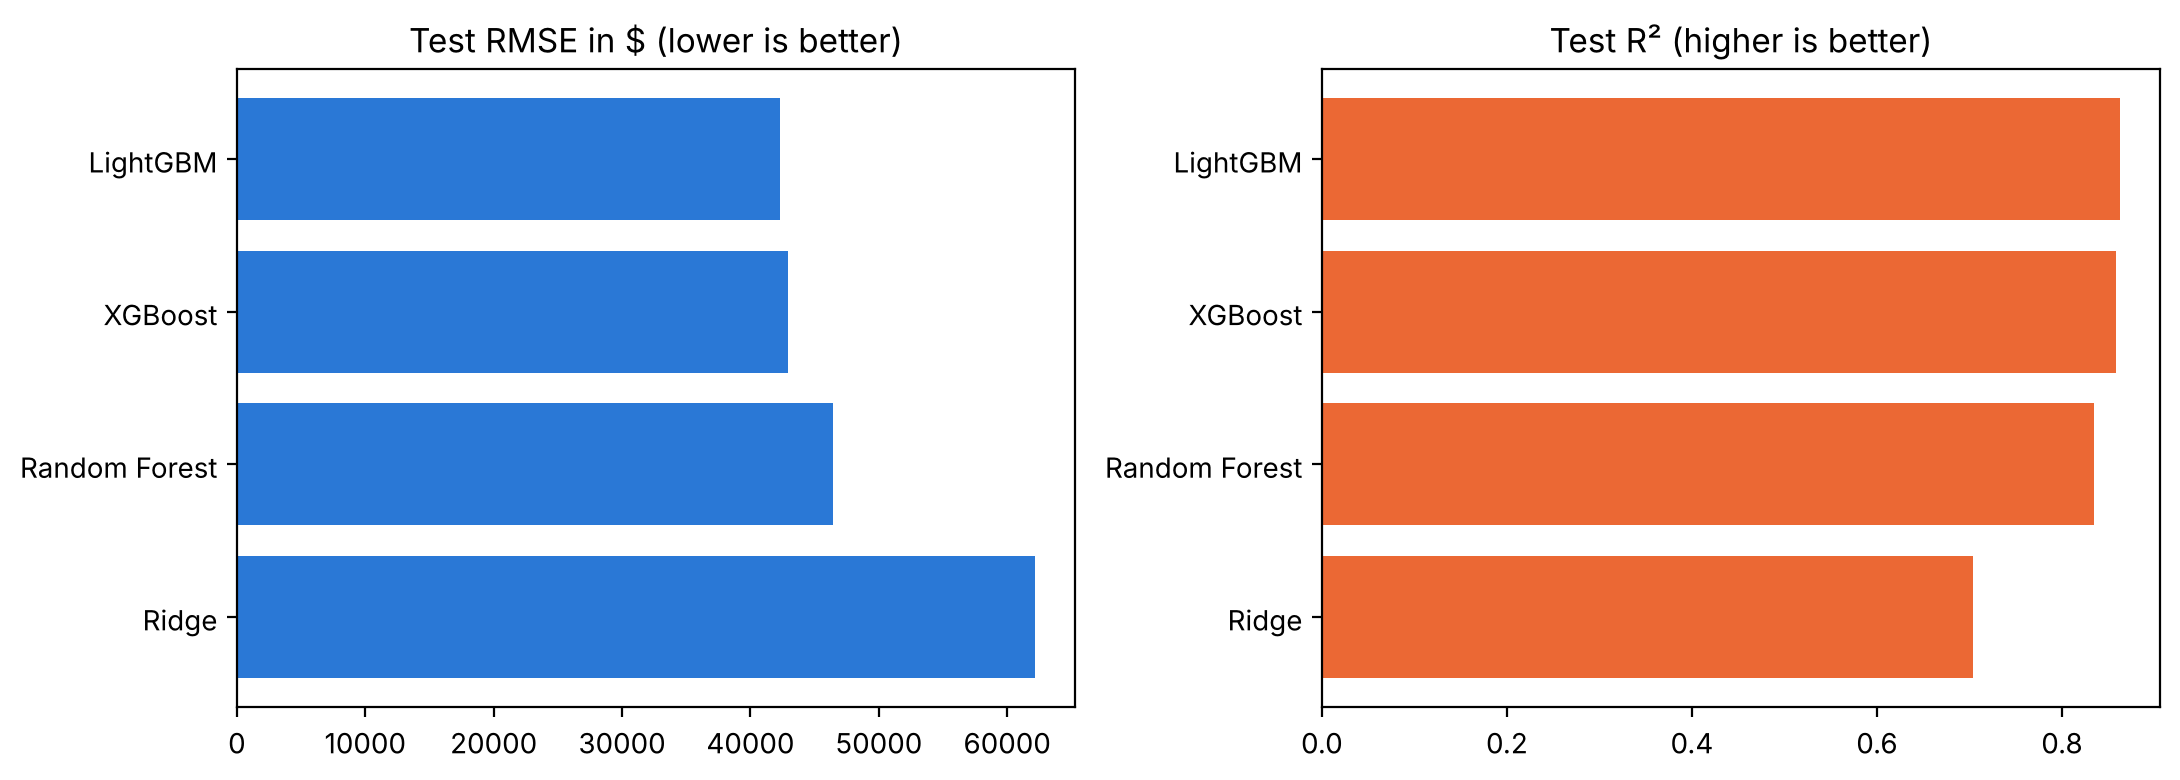

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = comparison["Model"]
ax[0].barh(order, comparison["Test RMSE ($)"], color="#2a78d6")
ax[0].set_title("Test RMSE in $ (lower is better)")
ax[0].invert_yaxis()
ax[1].barh(order, comparison["Test R2"], color="#eb6834")
ax[1].set_title("Test R² (higher is better)")
ax[1].invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Champion model
The champion is chosen by the **lowest tuned cross-validation RMSE** (the validation metric), not by the test score. The test set is then used only to confirm how it performs on new data.

In [9]:
champion_name = comparison.iloc[0]["Model"]
champion = tuned[champion_name].best_estimator_
print("Champion:", champion_name)
print("Best params:", {k.replace("model__", ""): v for k, v in tuned[champion_name].best_params_.items()})

final = evaluate(champion, X_test, y_test)
print({k: round(float(v), 3) for k, v in final.items()})

Champion: LightGBM
Best params: {'learning_rate': 0.03, 'n_estimators': 600, 'num_leaves': 63}


{'Test RMSE ($)': 42284.52, 'Test MAE ($)': 27930.633, 'Test R2': 0.863}


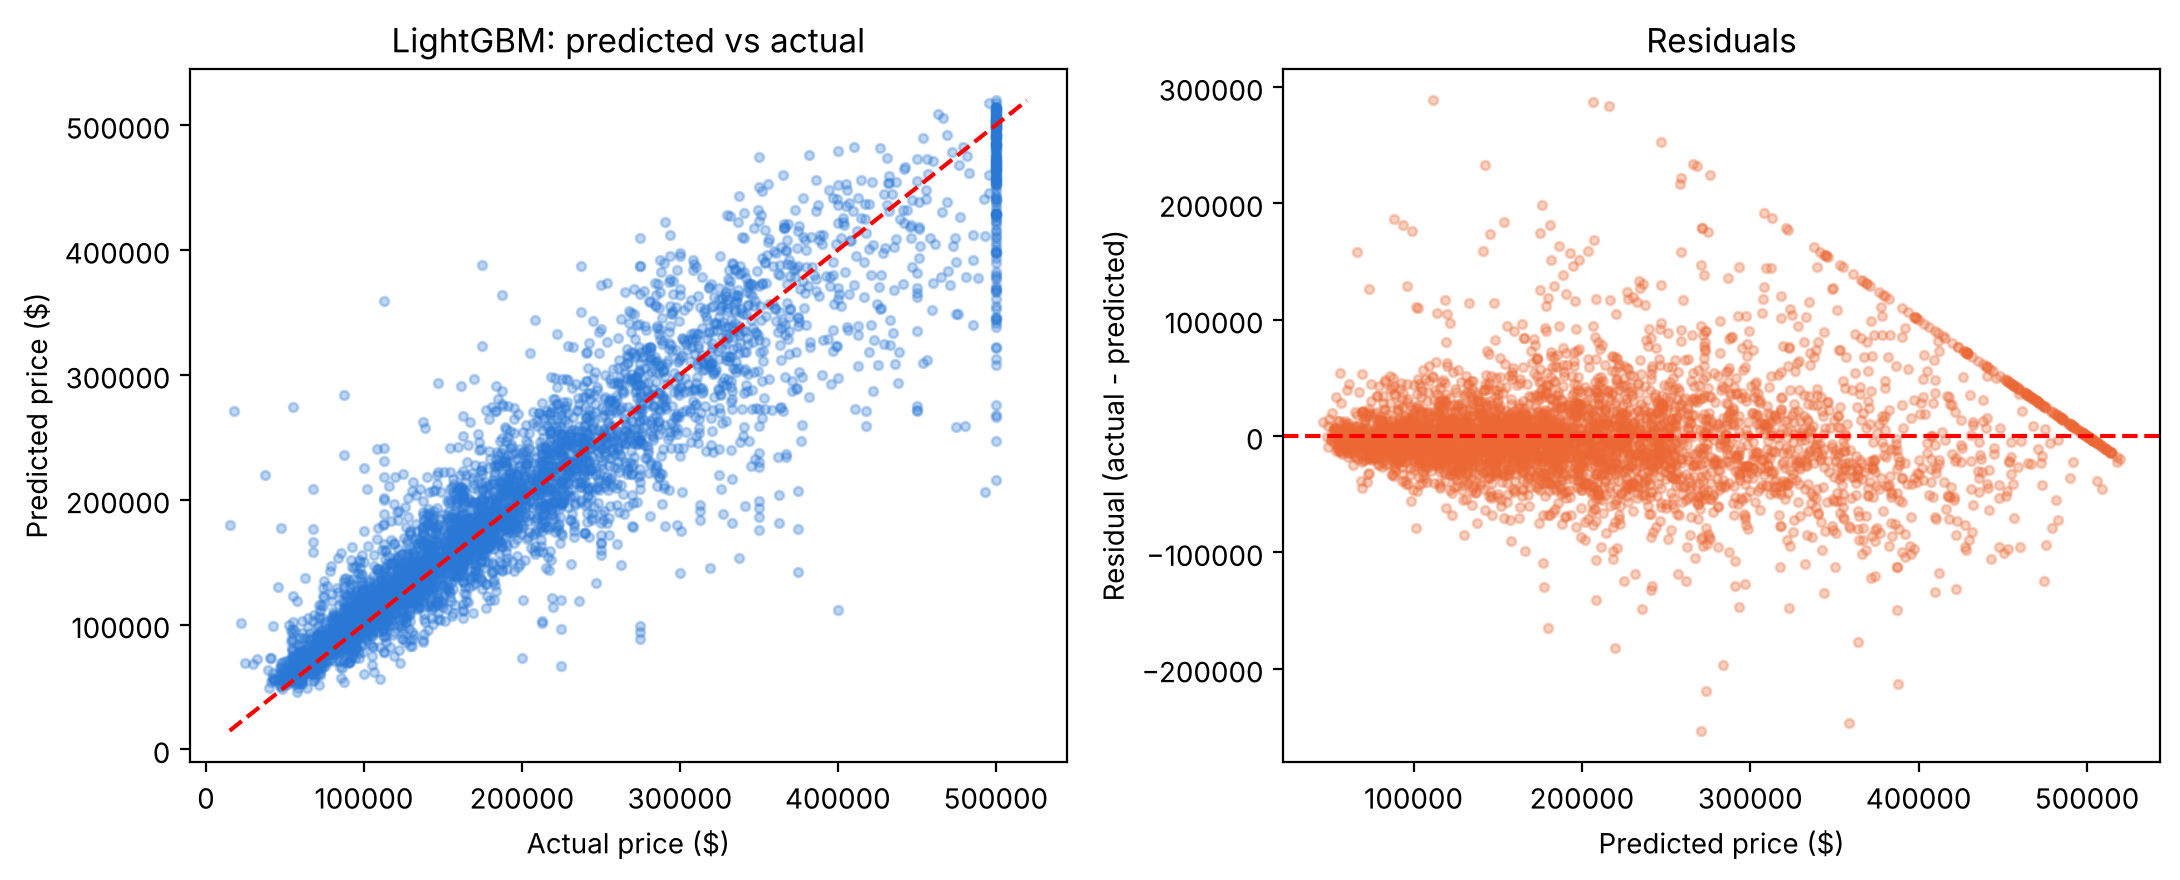

In [10]:
pred = champion.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

ax[0].scatter(y_test, pred, alpha=0.3, s=10, color="#2a78d6")
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
ax[0].plot(lims, lims, "r--")
ax[0].set_xlabel("Actual price ($)"); ax[0].set_ylabel("Predicted price ($)")
ax[0].set_title(f"{champion_name}: predicted vs actual")

ax[1].scatter(pred, y_test - pred, alpha=0.3, s=10, color="#eb6834")
ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Predicted price ($)"); ax[1].set_ylabel("Residual (actual - predicted)")
ax[1].set_title("Residuals")
plt.tight_layout()
plt.show()

## 7. Save the champion model
The saved file holds the **whole pipeline** (feature engineering + preprocessing + model), so raw housing rows can go straight in.

In [11]:
joblib.dump(champion, "champion_model.joblib", compress=3)
print("Saved champion_model.joblib (%.1f KB)" % (os.path.getsize("champion_model.joblib") / 1024))

# Sanity check: reload and confirm predictions match
loaded = joblib.load("champion_model.joblib")
assert np.allclose(loaded.predict(X_test), champion.predict(X_test))
print("Reload check passed.")
print("Predicted:", loaded.predict(X_test.head(3)).round(0))
print("Actual:   ", y_test.head(3).values)

Saved champion_model.joblib (1268.8 KB)


Reload check passed.
Predicted: [501360. 202745. 204310.]
Actual:    [500001. 162500. 204600.]


## 8. Conclusion
- I trained 4 different model types (Ridge, Random Forest, XGBoost, LightGBM) on the same preprocessed California Housing data from Task 03.
- GridSearchCV with 5-fold cross-validation tuned each model; the comparison table shows how much tuning improved each one.
- The champion was picked on validation (CV) RMSE and then checked once on the held-out test set.
- Tree-based and boosting models beat the linear model because house prices depend on non-linear effects such as income and location.
- The champion pipeline is saved as `champion_model.joblib` and predicts directly from raw housing columns.

**Limitations / next steps:** the grids are small to keep the run fast, so Optuna or wider grids could improve accuracy a little more. House values in this dataset are capped at $500,000, which limits how well any model can predict the most expensive districts.